In [30]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix


In [31]:
df_features = pd.read_csv(r"D:\Aswini\EDA\EV_charging\evcharging\Data\EVChargingRecords_Features.csv").drop(columns=["Unnamed: 0"])

In [32]:
df_features.isnull().sum()

UserID              0
ChargerID           0
ChargerCompany      0
Location            0
ChargerType         0
StartDay            0
StartTime           0
EndDay              0
EndTime             0
StartDatetime       0
EndDatetime         0
Duration            0
Demand              0
Duration_seconds    0
Duration_minutes    0
Duration_hours      0
is_anomaly          0
start day           0
start month         0
end day             0
end month           0
year                0
day_of_week         0
is_weekend          0
time_of_day         0
prev_sessions       0
HighDemand          0
dtype: int64

In [33]:
# --- Step 2: Defining predictors and target ---
X = df_features.drop(columns=['Demand','HighDemand','UserID','ChargerID'])  # drop target + IDs
y = df_features['HighDemand']

# --- Step 3: Train/Test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

# --- Step 4: Preprocessing pipeline ---
categorical_columns = ['ChargerCompany','Location','ChargerType','StartDay','StartTime','EndDay','EndTime','time_of_day']
numerical_columns   = ['Duration','Duration_seconds','Duration_minutes','Duration_hours','prev_sessions']
ordinal_columns     = ['start day','start month','end day','end month','year','day_of_week','is_weekend','is_anomaly']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns),
        ('num', StandardScaler(), numerical_columns),
        ('ord', OrdinalEncoder(), ordinal_columns)
    ],
    remainder='drop'
)

# --- Step 5: Fit preprocessing ---
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed  = preprocessor.transform(X_test)

# --- Step 6: Handling imbalance with SMOTE ---
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_preprocessed, y_train)


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Train
lr = LogisticRegression(max_iter=5000, solver='saga', random_state=42)
lr.fit(X_train_res, y_train_res)

# Predict
y_pred_lr = lr.predict(X_test_preprocessed)
y_prob_lr = lr.predict_proba(X_test_preprocessed)[:,1]

# Evaluate
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))


Logistic Regression Results
Accuracy: 0.8203314610637266
Precision: 0.8150825037501704
Recall: 0.8287576261785913
F1: 0.8218631832244757
ROC-AUC: 0.8965976582085605

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.81      0.82      7209
           1       0.82      0.83      0.82      7212

    accuracy                           0.82     14421
   macro avg       0.82      0.82      0.82     14421
weighted avg       0.82      0.82      0.82     14421


Confusion Matrix:
 [[5853 1356]
 [1235 5977]]


In [35]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_res, y_train_res)

y_pred_dt = dt.predict(X_test_preprocessed)
y_prob_dt = dt.predict_proba(X_test_preprocessed)[:,1]

print("Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))


Decision Tree Results
Accuracy: 0.8901601830663616
Precision: 0.879757085020243
Recall: 0.903910149750416
F1: 0.8916700861715223
ROC-AUC: 0.8901573220662192

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.88      0.89      7209
           1       0.88      0.90      0.89      7212

    accuracy                           0.89     14421
   macro avg       0.89      0.89      0.89     14421
weighted avg       0.89      0.89      0.89     14421


Confusion Matrix:
 [[6318  891]
 [ 693 6519]]


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train_res, y_train_res)

# --- Step 8: Predict on preprocessed test set ---
y_pred_rf = rf.predict(X_test_preprocessed)
y_prob_rf = rf.predict_proba(X_test_preprocessed)[:,1]

# --- Step 9: Evaluate ---
print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))


Random Forest Results
Accuracy: 0.8932806324110671
Precision: 0.8631417232108565
Recall: 0.9348308374930671
F1: 0.8975570791453106
ROC-AUC: 0.9505738728481308

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.85      0.89      7209
           1       0.86      0.93      0.90      7212

    accuracy                           0.89     14421
   macro avg       0.90      0.89      0.89     14421
weighted avg       0.90      0.89      0.89     14421


Confusion Matrix:
 [[6140 1069]
 [ 470 6742]]


In [37]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train_res, y_train_res)

y_pred_knn = knn.predict(X_test_preprocessed)
y_prob_knn = knn.predict_proba(X_test_preprocessed)[:,1]

print("KNN Results")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1:", f1_score(y_test, y_pred_knn))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))


KNN Results
Accuracy: 0.8018167949518064
Precision: 0.7897258450891669
Recall: 0.8227953410981698
F1: 0.8059214993888361
ROC-AUC: 0.8727268604205919

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.78      0.80      7209
           1       0.79      0.82      0.81      7212

    accuracy                           0.80     14421
   macro avg       0.80      0.80      0.80     14421
weighted avg       0.80      0.80      0.80     14421


Confusion Matrix:
 [[5629 1580]
 [1278 5934]]


In [38]:
from xgboost import XGBClassifier

xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train_res, y_train_res)

y_pred_xgb = xgb.predict(X_test_preprocessed)
y_prob_xgb = xgb.predict_proba(X_test_preprocessed)[:,1]

print("XGBoost Results")
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))


d:\Aswini\EDA\EV_charging\evcharging\Lib\site-packages\xgboost\training.py:200: UserWarning: [16:12:35] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Results
Accuracy: 0.9007003675195895
Precision: 0.8763020833333334
Recall: 0.9331669439822518
F1: 0.9038409884501746
ROC-AUC: 0.9607370043469574

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.87      0.90      7209
           1       0.88      0.93      0.90      7212

    accuracy                           0.90     14421
   macro avg       0.90      0.90      0.90     14421
weighted avg       0.90      0.90      0.90     14421


Confusion Matrix:
 [[6259  950]
 [ 482 6730]]


In [39]:
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Train LightGBM
lgb = LGBMClassifier(
    random_state=42,
    verbosity=-1
)

lgb.fit(X_train_res, y_train_res)

# Predictions
y_pred_lgb = lgb.predict(X_test_preprocessed)
y_prob_lgb = lgb.predict_proba(X_test_preprocessed)[:, 1]

# Evaluation
print("LightGBM Results")
print("Accuracy:", accuracy_score(y_test, y_pred_lgb))
print("Precision:", precision_score(y_test, y_pred_lgb))
print("Recall:", recall_score(y_test, y_pred_lgb))
print("F1:", f1_score(y_test, y_pred_lgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lgb))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_lgb))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_lgb))

LightGBM Results
Accuracy: 0.9004923375632757
Precision: 0.8760578049733108
Recall: 0.9330282861896838
F1: 0.903646008191768
ROC-AUC: 0.9606200328716487

Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.87      0.90      7209
           1       0.88      0.93      0.90      7212

    accuracy                           0.90     14421
   macro avg       0.90      0.90      0.90     14421
weighted avg       0.90      0.90      0.90     14421


Confusion Matrix:

[[6257  952]
 [ 483 6729]]


## Model Comparison

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---------|---------:|---------:|---------:|---------:|---------:|
| Logistic Regression | 0.8203 | 0.8151 | 0.8288 | 0.8219 | 0.8966 |
| KNN | 0.8018 | 0.7897 | 0.8228 | 0.8059 | 0.8727 |
| Decision Tree | 0.8902 | 0.8798 | 0.9039 | 0.8917 | 0.8902 |
| Random Forest | 0.8933 | 0.8631 | **0.9348** | 0.8976 | 0.9506 |
| XGBoost | **0.9007** | **0.8763** | 0.9332 | **0.9038** | **0.9607** |
| LightGBM | 0.9005 | 0.8761 | 0.9330 | 0.9036 | 0.9606 |


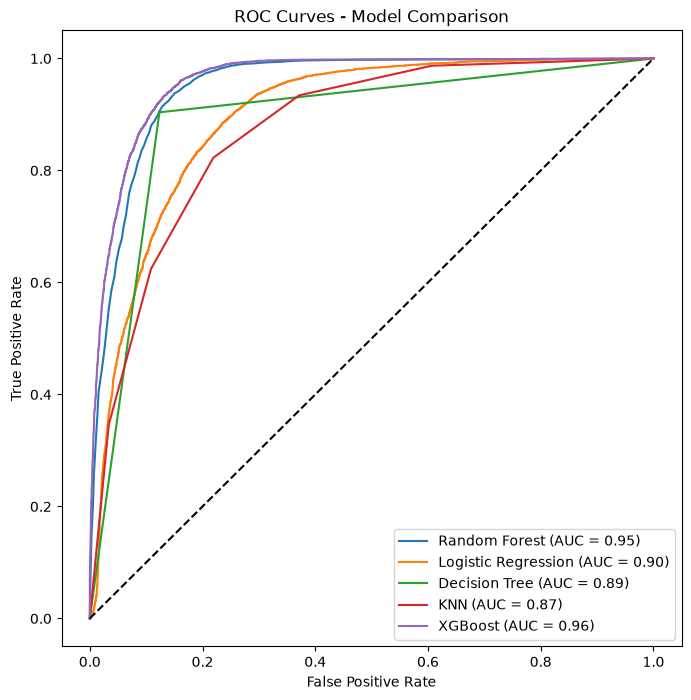

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8,8))

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.2f})')

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.2f})')

# Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_prob_dt):.2f})')

# KNN
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
plt.plot(fpr_knn, tpr_knn, label=f'KNN (AUC = {roc_auc_score(y_test, y_prob_knn):.2f})')

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.2f})')

# Plot settings
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend(loc="lower right")
plt.show()


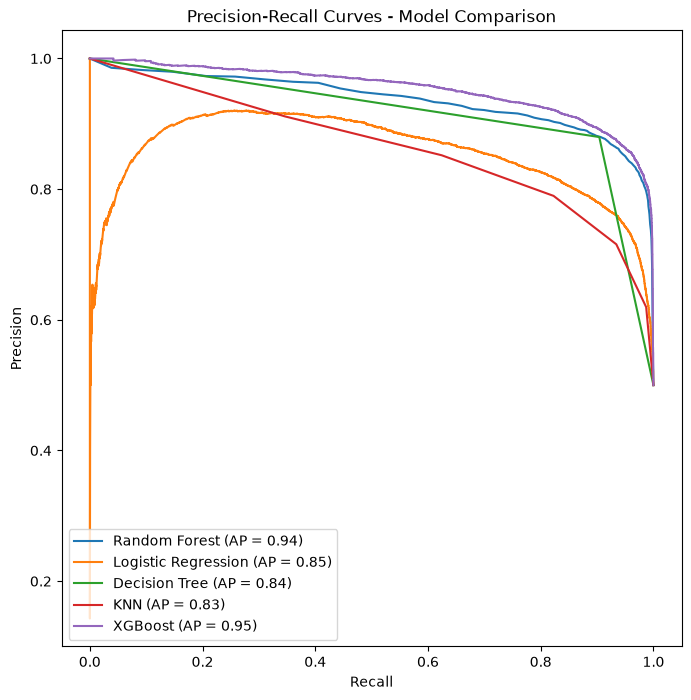

In [41]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8,8))

# Random Forest
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
plt.plot(rec_rf, prec_rf, label=f'Random Forest (AP = {average_precision_score(y_test, y_prob_rf):.2f})')

# Logistic Regression
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
plt.plot(rec_lr, prec_lr, label=f'Logistic Regression (AP = {average_precision_score(y_test, y_prob_lr):.2f})')

# Decision Tree
prec_dt, rec_dt, _ = precision_recall_curve(y_test, y_prob_dt)
plt.plot(rec_dt, prec_dt, label=f'Decision Tree (AP = {average_precision_score(y_test, y_prob_dt):.2f})')

# KNN
prec_knn, rec_knn, _ = precision_recall_curve(y_test, y_prob_knn)
plt.plot(rec_knn, prec_knn, label=f'KNN (AP = {average_precision_score(y_test, y_prob_knn):.2f})')

# XGBoost
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)
plt.plot(rec_xgb, prec_xgb, label=f'XGBoost (AP = {average_precision_score(y_test, y_prob_xgb):.2f})')

# Plot settings
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves - Model Comparison')
plt.legend(loc="lower left")
plt.show()


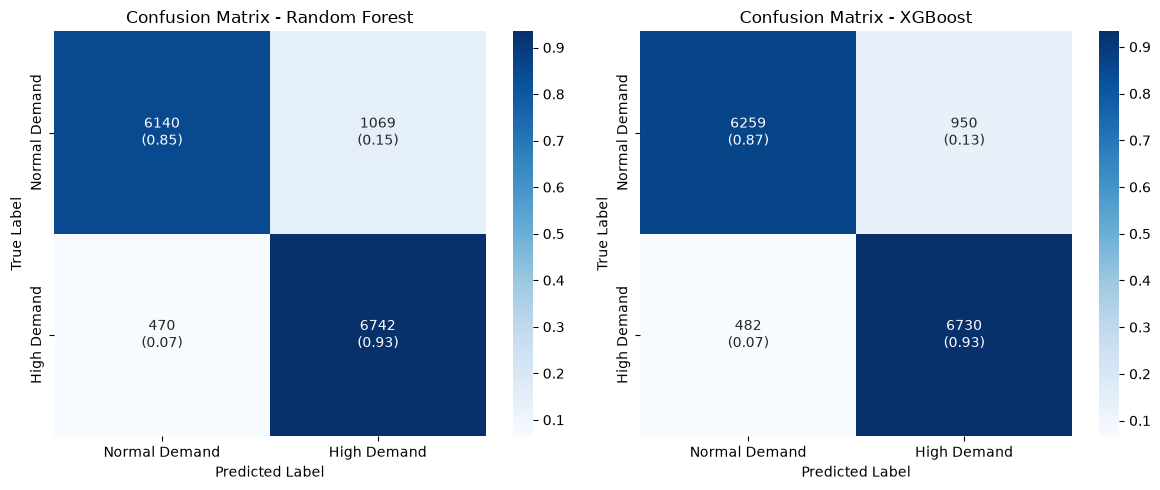

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# Compute raw and normalized confusion matrices
cm_rf_raw = confusion_matrix(y_test, y_pred_rf)
cm_rf_norm = confusion_matrix(y_test, y_pred_rf, normalize='true')

cm_xgb_raw = confusion_matrix(y_test, y_pred_xgb)
cm_xgb_norm = confusion_matrix(y_test, y_pred_xgb, normalize='true')

# Create combined annotations (raw + percentage)
annot_rf = np.empty_like(cm_rf_raw).astype(str)
for i in range(cm_rf_raw.shape[0]):
    for j in range(cm_rf_raw.shape[1]):
        annot_rf[i, j] = f"{cm_rf_raw[i, j]}\n({cm_rf_norm[i, j]:.2f})"

annot_xgb = np.empty_like(cm_xgb_raw).astype(str)
for i in range(cm_xgb_raw.shape[0]):
    for j in range(cm_xgb_raw.shape[1]):
        annot_xgb[i, j] = f"{cm_xgb_raw[i, j]}\n({cm_xgb_norm[i, j]:.2f})"

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.heatmap(cm_rf_norm, annot=annot_rf, fmt='', cmap='Blues',
            xticklabels=['Normal Demand','High Demand'],
            yticklabels=['Normal Demand','High Demand'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix - Random Forest')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(cm_xgb_norm, annot=annot_xgb, fmt='', cmap='Blues',
            xticklabels=['Normal Demand','High Demand'],
            yticklabels=['Normal Demand','High Demand'],
            ax=axes[1])
axes[1].set_title('Confusion Matrix - XGBoost')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

In [43]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

def threshold_analysis(y_true, y_prob, model_name, thresholds=[0.3, 0.5, 0.7]):
    results = []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        cm = confusion_matrix(y_true, y_pred)
        tn, fp, fn, tp = cm.ravel()
        precision = precision_score(y_true, y_pred)
        recall = recall_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred)
        results.append({
            "Model": model_name,
            "Threshold": t,
            "TN (raw)": tn,
            "FP (raw)": fp,
            "FN (raw)": fn,
            "TP (raw)": tp,
            "TN (%)": tn / (tn + fp),
            "FP (%)": fp / (tn + fp),
            "FN (%)": fn / (fn + tp),
            "TP (%)": tp / (fn + tp),
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })
    return pd.DataFrame(results)

# Run for Random Forest and XGBoost
rf_results = threshold_analysis(y_test, y_prob_rf, "Random Forest")
xgb_results = threshold_analysis(y_test, y_prob_xgb, "XGBoost")

# Combine into one table
comparison = pd.concat([rf_results, xgb_results])
print(comparison)


           Model  Threshold  TN (raw)  FP (raw)  FN (raw)  TP (raw)    TN (%)  \
0  Random Forest        0.3      5656      1553       168      7044  0.784575   
1  Random Forest        0.5      6126      1083       448      6764  0.849771   
2  Random Forest        0.7      6458       751       974      6238  0.895825   
0        XGBoost        0.3      5852      1357       197      7015  0.811763   
1        XGBoost        0.5      6259       950       482      6730  0.868220   
2        XGBoost        0.7      6610       599      1048      6164  0.916909   

     FP (%)    FN (%)    TP (%)  Precision    Recall        F1  
0  0.215425  0.023295  0.976705   0.819356  0.976705  0.891138  
1  0.150229  0.062119  0.937881   0.861985  0.937881  0.898333  
2  0.104175  0.135053  0.864947   0.892545  0.864947  0.878530  
0  0.188237  0.027316  0.972684   0.837912  0.972684  0.900282  
1  0.131780  0.066833  0.933167   0.876302  0.933167  0.903841  
2  0.083091  0.145313  0.854687   0.911430

In [44]:
# Count of High vs Normal demand in the dataset - checking class imbalance
print("Target distribution:")
print(df_features['HighDemand'].value_counts())
print(df_features['HighDemand'].value_counts(normalize=True))

Target distribution:
HighDemand
1    36058
0    36047
Name: count, dtype: int64
HighDemand
1    0.500076
0    0.499924
Name: proportion, dtype: float64


In [45]:
#Checking class imbalance
print("Random Forest predicted distribution:", pd.Series(y_pred_rf).value_counts(normalize=True))
print("XGBoost predicted distribution:", pd.Series(y_pred_xgb).value_counts(normalize=True))

Random Forest predicted distribution: 1    0.541641
0    0.458359
Name: proportion, dtype: float64
XGBoost predicted distribution: 1    0.532557
0    0.467443
Name: proportion, dtype: float64


In [46]:
X_train = X_train.loc[:, ~X_train.columns.str.contains('^Unnamed')]
X_test  = X_test.loc[:, ~X_test.columns.str.contains('^Unnamed')]


In [47]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
d = df_features.copy()
st = pd.to_datetime(d["StartDatetime"])
d["hour"] = st.dt.hour
d["start_month"] = st.dt.month
d["start_day"] = st.dt.day

y = d["HighDemand"]
cat = ["Location", "time_of_day"]
num = ["ChargerCompany", "ChargerType", "Duration_minutes", "hour",
       "start_month", "start_day", "day_of_week", "is_weekend"]

preprocessor = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat)],
    remainder="passthrough",
)
X_encoded = preprocessor.fit_transform(d[cat + num])      # 26 columns instead of 221,000

rf = RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_leaf=10,
                            n_jobs=2, random_state=42)
rf_scores = cross_val_score(rf, X_encoded, y,
                            cv=StratifiedKFold(5, shuffle=True, random_state=42),
                            scoring="accuracy")
print("Random Forest CV Accuracy:", rf_scores.mean())

Random Forest CV Accuracy: 0.893433187712364


In [48]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    n_jobs=2,
    random_state=42,
)

cv = StratifiedKFold(5, shuffle=True, random_state=42)

xgb_acc = cross_val_score(xgb, X_encoded, y, cv=cv, scoring="accuracy")
xgb_auc = cross_val_score(xgb, X_encoded, y, cv=cv, scoring="roc_auc")

print("XGBoost CV Accuracy:", xgb_acc.round(3), "mean", xgb_acc.mean().round(3))
print("XGBoost CV ROC-AUC: ", xgb_auc.round(3), "mean", xgb_auc.mean().round(3))

XGBoost CV Accuracy: [0.894 0.893 0.895 0.896 0.896] mean 0.895
XGBoost CV ROC-AUC:  [0.956 0.956 0.957 0.959 0.958] mean 0.957


In [49]:
import pickle
pickle.dump((xgb, preprocessor), open("classification_model.pkl", "wb"))

In [50]:
xgb.fit(X_encoded, y)                      # fit on the 26-column features
print(xgb.n_features_in_, X_encoded.shape[1])   # must match
pickle.dump((xgb, preprocessor), open("classification_model.pkl", "wb"))

26 26
